# AI-Powered Network Intrusion Detection
## 1. Dataset Exploration

This notebook explores the UNSW-NB15 dataset, checks data quality, and examines normal versus malicious traffic.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

In [2]:
TRAIN_PATH = '../data/processed/UNSW_NB15_training-set.csv'
TEST_PATH = '../data/processed/UNSW_NB15_testing-set.csv'

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print('Training shape:', train_df.shape)
print('Testing shape:', test_df.shape)

Training shape: (175341, 45)
Testing shape: (82332, 45)


In [3]:
# 1. Inspect the first five records
display(train_df.head())

# 2. Check column data types
print("DATA TYPES")
display(train_df.dtypes.value_counts())

# 3. Check missing values
print("MISSING VALUES")
missing = train_df.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False))

# 4. Check duplicate rows
print("DUPLICATE ROWS")
print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())

# 5. Summary statistics for numerical features
print("NUMERICAL SUMMARY")
display(train_df.describe().T)

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


DATA TYPES


int64      30
float64    11
str         4
Name: count, dtype: int64

MISSING VALUES


Series([], dtype: int64)

DUPLICATE ROWS
Training duplicates: 0
Testing duplicates: 0
NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
id,175341.0,8.767100e+04,5.061673e+04,1.0,43836.000000,87671.000000,1.315060e+05,1.753410e+05
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786140,3225.806520,1.250000e+05,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000000,254.000000,2.540000e+02,2.550000e+02
dttl,175341.0,7.960957e+01,1.105069e+02,0.0,0.000000,29.000000,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338870,879674.750000,8.888889e+07,5.988000e+09


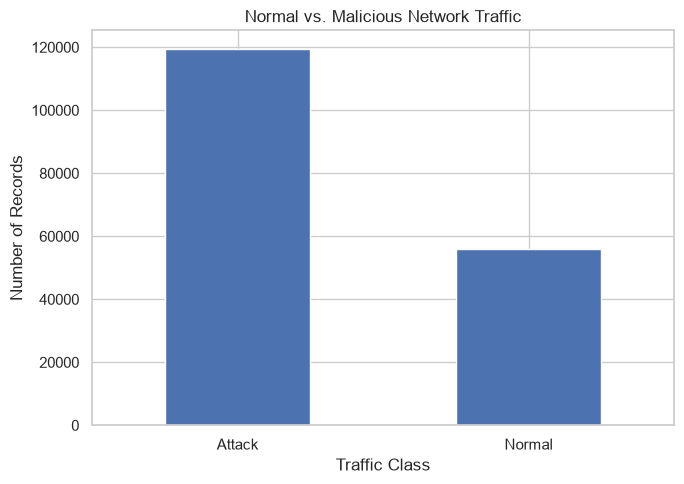

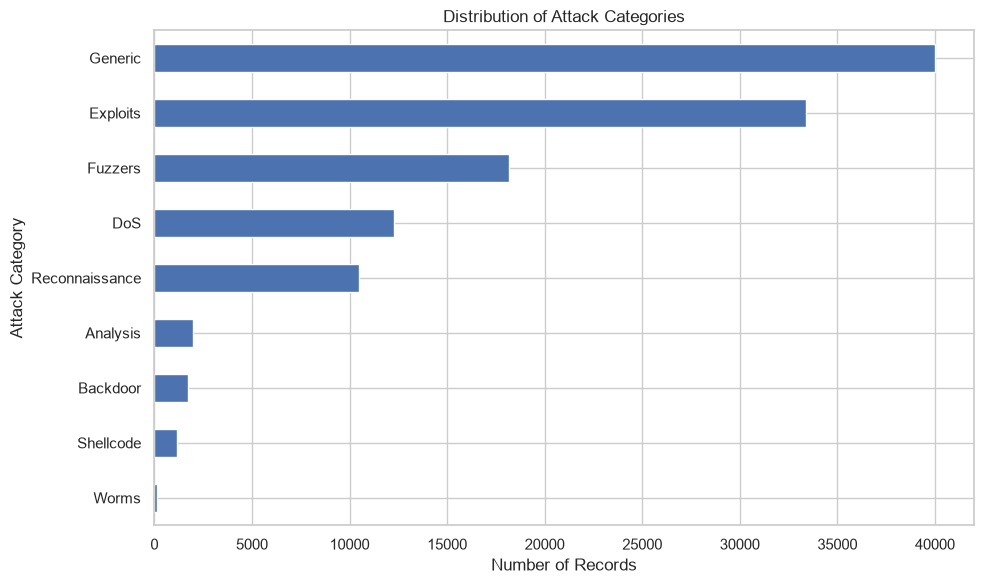

,Record Count
attack_cat,
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133
Worms,130


In [4]:
# Count normal and malicious traffic
label_counts = train_df["label"].map({
    0: "Normal",
    1: "Attack"
}).value_counts()

plt.figure(figsize=(7, 5))
label_counts.plot(kind="bar")
plt.title("Normal vs. Malicious Network Traffic")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Examine attack categories
attack_counts = (
    train_df.loc[train_df["label"] == 1, "attack_cat"]
    .value_counts()
)

plt.figure(figsize=(10, 6))
attack_counts.sort_values().plot(kind="barh")
plt.title("Distribution of Attack Categories")
plt.xlabel("Number of Records")
plt.ylabel("Attack Category")
plt.tight_layout()
plt.show()

display(attack_counts.to_frame(name="Record Count"))

In [5]:
# Identify categorical columns
categorical_cols = train_df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

# Inspect the number of unique values
for col in categorical_cols:
    print(f"\n{col}: {train_df[col].nunique()} unique values")
    print(train_df[col].value_counts().head(10))

Categorical columns: ['proto', 'service', 'state', 'attack_cat']

proto: 133 unique values
proto
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
sctp       1150
any         300
gre         225
sun-nd      201
swipe       201
Name: count, dtype: int64

service: 13 unique values
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
Name: count, dtype: int64

state: 9 unique values
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64

attack_cat: 10 unique values
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: in

In [6]:
# Separate target labels
y_train = train_df["label"].astype(int)
y_test = test_df["label"].astype(int)

# Remove target and leakage-prone identifier/category columns
columns_to_drop = ["id", "label", "attack_cat"]

X_train = train_df.drop(columns=columns_to_drop)
X_test = test_df.drop(columns=columns_to_drop)

# Identify categorical columns for later encoding
categorical_cols = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Identify numerical columns
numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Categorical features:", categorical_cols)
print("Number of numerical features:", len(numerical_cols))

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

# Confirm feature columns match
assert X_train.columns.tolist() == X_test.columns.tolist()
print("\nFeature columns match between training and testing sets.")

Training features: (175341, 42)
Testing features: (82332, 42)
Categorical features: ['proto', 'service', 'state']
Number of numerical features: 39

Training target distribution:
label
0     56000
1    119341
Name: count, dtype: int64

Testing target distribution:
label
0    37000
1    45332
Name: count, dtype: int64

Feature columns match between training and testing sets.


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data without fitting on it
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Sparse matrix:", hasattr(X_train_processed, "toarray"))
print("Preprocessing completed successfully.")

Processed training shape: (175341, 194)
Processed testing shape: (82332, 194)
Sparse matrix: True
Preprocessing completed successfully.


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
import time

# Initialize the baseline model
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
start_time = time.time()
logistic_model.fit(X_train_processed, y_train)
training_time = time.time() - start_time

# Predict test labels and attack probabilities
y_pred = logistic_model.predict(X_test_processed)
y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("LOGISTIC REGRESSION — TEST RESULTS")
print("-" * 40)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")
print(f"Training time: {training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

LOGISTIC REGRESSION — TEST RESULTS
----------------------------------------
Accuracy:  0.8353
Precision: 0.8020
Recall:    0.9306
F1-score:  0.8615
ROC-AUC:   0.9560
Training time: 13.49 seconds

Classification Report:
              precision    recall  f1-score   support

      Normal       0.89      0.72      0.80     37000
      Attack       0.80      0.93      0.86     45332

    accuracy                           0.84     82332
   macro avg       0.85      0.82      0.83     82332
weighted avg       0.84      0.84      0.83     82332



Confusion Matrix:
[[26588 10412]
 [ 3148 42184]]


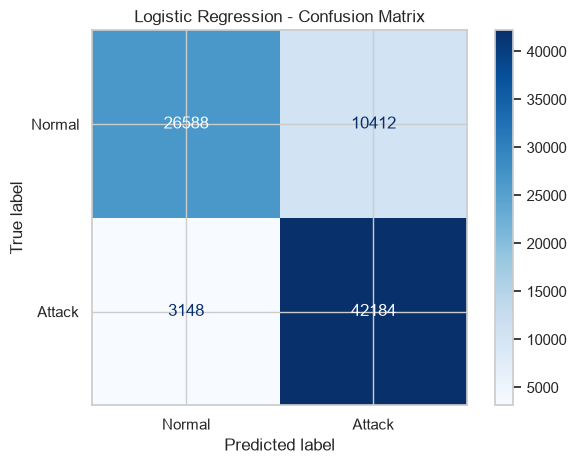

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display counts and plot
print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

Confusion Matrix:
[[26588 10412]
 [ 3148 42184]]


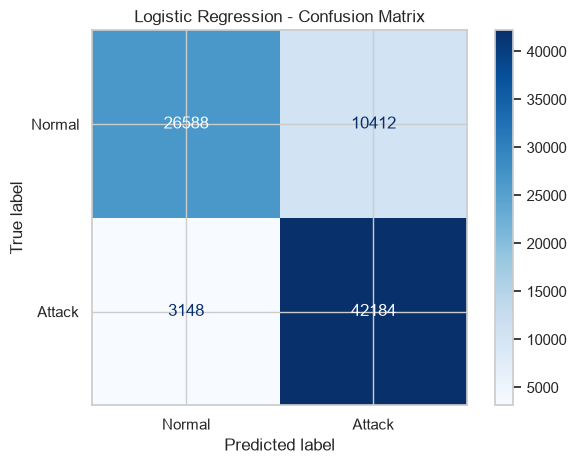

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from scipy.sparse import issparse
import pandas as pd
import time

# HistGradientBoosting requires dense input.
# Convert only if needed; other models can use the sparse matrix.
X_train_dense = X_train_processed.toarray() if issparse(X_train_processed) else X_train_processed
X_test_dense = X_test_processed.toarray() if issparse(X_test_processed) else X_test_processed

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=100, random_state=42
    )
}

results = []

for name, model in models.items():
    print(f"Training {name}...")

    # Use dense arrays for all models in this comparison
    start = time.time()
    model.fit(X_train_dense, y_train)
    elapsed = time.time() - start

    predictions = model.predict(X_test_dense)
    probabilities = model.predict_proba(X_test_dense)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Training Time (s)": elapsed
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training HistGradientBoosting...


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [14]:
# Display the model comparison table
from IPython.display import display as show_table

display_name = results_df.round(4)
show_table(display_name)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s)
0,Random Forest,0.8921,0.8510,0.9746,0.9086,0.9804,13.7160
1,HistGradientBoosting,0.8748,0.8225,0.9853,0.8966,0.9854,14.3514
2,Decision Tree,0.8614,0.8168,0.9646,0.8845,0.8515,13.3348
3,Logistic Regression,0.8356,0.8024,0.9304,0.8617,0.9559,18.1883


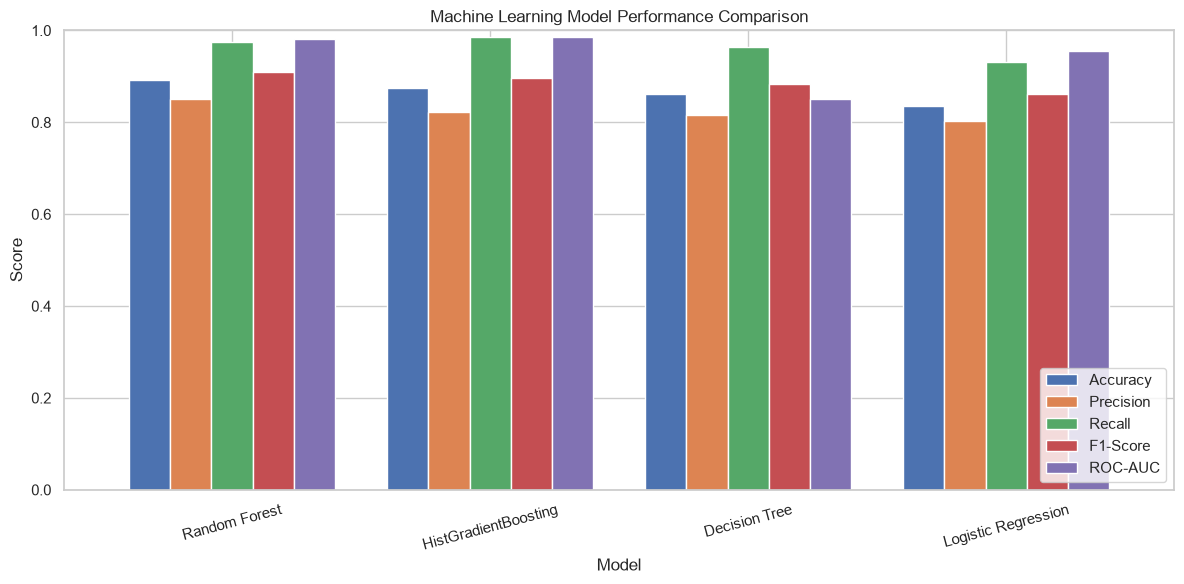

In [15]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

plot_df = results_df.set_index("Model")[metrics]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Machine Learning Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=15)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [16]:
from pathlib import Path

# Create the results directory if it does not exist
results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison table
results_df.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")
print("File:", (results_dir / "model_comparison.csv").resolve())

# Display the saved results
from IPython.display import display as show_table
show_table(results_df.round(4))

Model comparison saved successfully.
File: C:\Users\Zolla\Documents\Portfolio Projects\ai-intrusion-detection\results\model_comparison.csv


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s)
0,Random Forest,0.8921,0.8510,0.9746,0.9086,0.9804,13.7160
1,HistGradientBoosting,0.8748,0.8225,0.9853,0.8966,0.9854,14.3514
2,Decision Tree,0.8614,0.8168,0.9646,0.8845,0.8515,13.3348
3,Logistic Regression,0.8356,0.8024,0.9304,0.8617,0.9559,18.1883


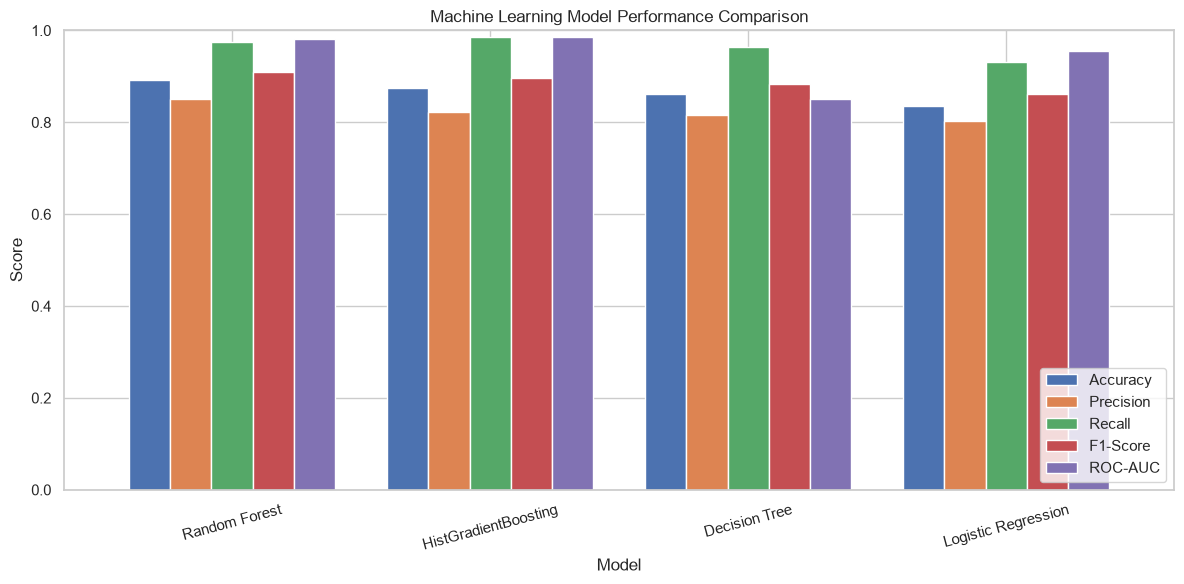

Chart saved successfully!
File location: C:\Users\Zolla\Documents\Portfolio Projects\ai-intrusion-detection\results\figures\model_performance_comparison.png


In [17]:

from pathlib import Path
import matplotlib.pyplot as plt

# Create the figures directory
figures_dir = Path("../results/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Select evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
plot_df = results_df.set_index("Model")[metrics]

# Generate the comparison chart
ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Machine Learning Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=15)
ax.legend(loc="lower right")

plt.tight_layout()

# Save the chart at high resolution
chart_path = figures_dir / "model_performance_comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("File location:", chart_path.resolve())


In [18]:

from pathlib import Path
import joblib
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Create the models directory
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Build the final model using the existing fitted preprocessor
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using the original training data
final_model.fit(X_train, y_train)

# Save the complete pipeline
model_path = models_dir / "intrusion_detection_pipeline.joblib"
joblib.dump(final_model, model_path)

print("Final model trained and saved successfully.")
print("Model location:", model_path.resolve())


Final model trained and saved successfully.
Model location: C:\Users\Zolla\Documents\Portfolio Projects\ai-intrusion-detection\models\intrusion_detection_pipeline.joblib
